# 01 | EDA and Baseline
*Project 2 — Machine Learning: From Data to Predictions*

**Project:** Predicting PEM fuel-cell cell voltage  
**Dataset:** Polarization-curve records from Hamidi, Haghighi & Askari (2020)  
**Target:** `cell_voltage` (V)  
**Problem type:** Supervised regression

This notebook follows the first template stage: frame the question, inspect the raw data, assess quality and leakage risks, explore relationships, create one fixed group-aware holdout, and establish a baseline. The held-out source files are not used for model selection.

---
## 0. Setup

Run this notebook from the project root or from `notebooks/`. The helper loader selects polarization-curve CSVs and excludes other tables with incompatible schemas.

In [1]:
from pathlib import Path
import sys, warnings, json
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from project_utils import load_polarization_data

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
FEATURES = ["current_density", "pressure", "relative_humidity", "test_family", "operating_set"]
TARGET = "cell_voltage"
GROUP = "source_file"

data = load_polarization_data()
print(f"Loaded {len(data):,} observations from {data[GROUP].nunique()} source files "
      f"across {data['test_family'].nunique()} test families.")

Loaded 5,005 observations from 26 source files across 9 test families.


---
## 1. Frame the problem

**Question:** Can a supervised model predict PEM fuel-cell cell voltage (V) from current density and recorded operating condition (context) when entire source files are held out?

**Intended user:** A fuel cell researcher or test engineer exploring experimental data and prioritizing follow-up analysis—not an operator relying on the model as a replacement for physical testing. Again, the model is a screening aid and not a substitute for a measured ploarization curve or an engineering safety limit.

**Target:** `cell_voltage` in volts (regression).

**Primary metric:** Mean absolute error (MAE), reported in volts. It is directly interpretable as the average absolute prediction error and treats over- and under-prediction symmetrically. RMSE is also reported to make larger errors more visible. For context, an MAE of 0.05 V would mean an average absolute miss of 50 mV; whether that is acceptable must be decided against the experiment's voltage tolerance.

**Validation unit:** `source_file`. Measurements from one curve are related, so a random row split could leak similar observations across training and test sets.

A false optimistic prediction can make a condition look better than it is; a pessimistic prediction can lead a researcher to overlook a promising condition. Therefore, model predictions should prioritize experiment selection and never be used as a sole basis for safety or deployment decisions.

The data include repeated points within measured curves. We hold out complete source files to reduce leakage from neighboring curve points. `power_density` is excluded because it is derived from current density and cell voltage, and would leak information about the target.

---
## 2. Load the raw data - Data audit

The source archive contains both polarization curves and electrochemical impedance spectroscopy (EIS) files. The project loader scans `data/raw/`, deliberately selects tables containing `current_density`, `cell_voltage`, and `power_density`, and creates a consistent modelling table. EIS tables are not combined with polarization curve records into this supervised task.

`power_density` is excluded from predictors because it is derived from current density and cell voltage. Using it would leak information about the target.


In [2]:
print("Shape:", data.shape)
print("Columns:", data.columns.tolist())
display(data.head())
print("\nDtypes:")
display(data.dtypes.rename("dtype").to_frame())
print("\nSource files:", data[GROUP].nunique())
print("Test families:", sorted(data["test_family"].unique()))

Shape: (5005, 7)
Columns: ['current_density', 'pressure', 'relative_humidity', 'test_family', 'source_file', 'cell_voltage', 'operating_set']


,current_density,pressure,relative_humidity,test_family,source_file,cell_voltage,operating_set
0,2550.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,Activation Test MEA Constant Current 0.25A/4.csv,0.296,not_recorded
1,2380.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,Activation Test MEA Constant Current 0.25A/4.csv,0.345,not_recorded
2,2180.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,Activation Test MEA Constant Current 0.25A/4.csv,0.395,not_recorded
3,1950.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,Activation Test MEA Constant Current 0.25A/4.csv,0.446,not_recorded
4,1690.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,Activation Test MEA Constant Current 0.25A/4.csv,0.495,not_recorded



Dtypes:


,dtype
current_density,float64
pressure,float64
relative_humidity,float64
test_family,str
source_file,str
cell_voltage,float64
operating_set,str



Source files: 26
Test families: ['Activation Test MEA Constant Current 0.25A', 'Activation Test MEA Constant Voltage 0.6V', 'Activation Test MEA Constant Voltage 0.6V-2', 'Activation Test MEA Constant Voltage 0.6V-3', 'Activation Test MEA Constant Voltage 0.6V-4', 'Activation Test MEA Cycling Potential', 'Activation Test MEA Standard Protocol', 'Activation Test MEA Standard Protocol (Repeat)', 'Standard Test of Nafion Membrane 112']


---
## 3. First look

One row represents a recorded point from a polarization experiment, with voltage, current density, and available operating context. The same source file may contain many related points.

In [3]:
display(data.groupby(GROUP).size().describe().rename("rows_per_source_file").to_frame())
display(data.groupby("test_family").agg(
    observations=(TARGET, "size"),
    source_files=(GROUP, "nunique"),
    voltage_mean_V=(TARGET, "mean"),
    voltage_std_V=(TARGET, "std")
).sort_values("observations", ascending=False))

,rows_per_source_file
count,26.000000
mean,192.500000
std,138.616377
min,49.000000
25%,140.000000
50%,142.500000
75%,144.750000
max,651.000000


,observations,source_files,voltage_mean_V,voltage_std_V
test_family,,,,
Standard Test of Nafion Membrane 112,1213,2,0.599542,0.226279
Activation Test MEA Standard Protocol,657,3,0.611502,0.225561
Activation Test MEA Standard Protocol (Repeat),590,3,0.618847,0.231822
Activation Test MEA Constant Current 0.25A,559,3,0.610977,0.226225
Activation Test MEA Constant Voltage 0.6V-2,429,3,0.611291,0.228862
Activation Test MEA Constant Voltage 0.6V-4,425,3,0.613327,0.230050
Activation Test MEA Constant Voltage 0.6V-3,424,3,0.610790,0.227162
Activation Test MEA Constant Voltage 0.6V,416,3,0.616382,0.228217
Activation Test MEA Cycling Potential,292,3,0.596010,0.237910


---
## 4. Data quality

Check missingness, duplicate rows, numeric ranges, and source-file representation. The loader converts numeric fields explicitly and drops rows without the target or current density. Remaining missing predictor values are handled inside the model pipeline to avoid learning preprocessing values from held-out folds.

In [4]:
print("Missing values by column:")
display(data.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())
print("Exact duplicate rows:", int(data.duplicated().sum()))
display(data[["current_density", "cell_voltage", "pressure", "relative_humidity"]].describe().T)
print("Non-finite values in numeric columns:")
display((~np.isfinite(data[["current_density", "cell_voltage", "pressure", "relative_humidity"]])).sum().rename("non_finite_count").to_frame())

Missing values by column:


,missing_count
pressure,1580
relative_humidity,1580
current_density,0
test_family,0
source_file,0
cell_voltage,0
operating_set,0


Exact duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
current_density,5005.0,956.037968,933.433492,0.000,156.000,734.000,1360.000,4650.00
cell_voltage,5005.0,0.608989,0.228238,0.143,0.418,0.615,0.807,1.03
pressure,3425.0,15.081752,8.156206,5.000,5.000,15.000,25.000,25.00
relative_humidity,3425.0,60.753285,28.667122,30.000,30.000,50.000,100.000,100.00


Non-finite values in numeric columns:


,non_finite_count
current_density,0
cell_voltage,0
pressure,1580
relative_humidity,1580


---
## 5. Columns that must go

- `source_file` is used to group observations for splitting and error analysis; it is not a predictor because it identifies the source record rather than a physical condition.
- `power_density` is excluded because it is derived from voltage and current density. Since voltage is the target, using power density could leak target information.
- `cell_voltage` is the target and must not appear in the feature matrix.

The modelling features are current density, pressure, relative humidity, test family, and operating set. Some operating fields may be missing or not recorded in every source.

---
## 6. The target

Inspect the distribution and quantiles of cell voltage. The target is continuous, so classification metrics and a class-balance analysis are not appropriate.

,cell_voltage
count,5005.000000
mean,0.608989
std,0.228238
min,0.143000
1%,0.225000
5%,0.250200
25%,0.418000
50%,0.615000
75%,0.807000
95%,0.962000


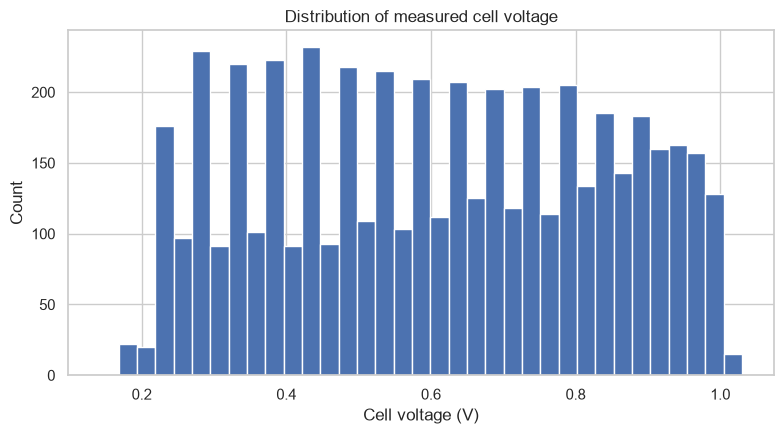

In [5]:
display(data[TARGET].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame())
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(data[TARGET].dropna(), bins=35, edgecolor="white")
ax.set(xlabel="Cell voltage (V)", ylabel="Count", title="Distribution of measured cell voltage")
fig.tight_layout()
fig.savefig(ROOT / "target_voltage_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 7. Features against the target - Exploratory plots

These plots are descriptive, not causal. Curves and measurements from one file are related, and operating conditions can be confounded with protocol or test family.

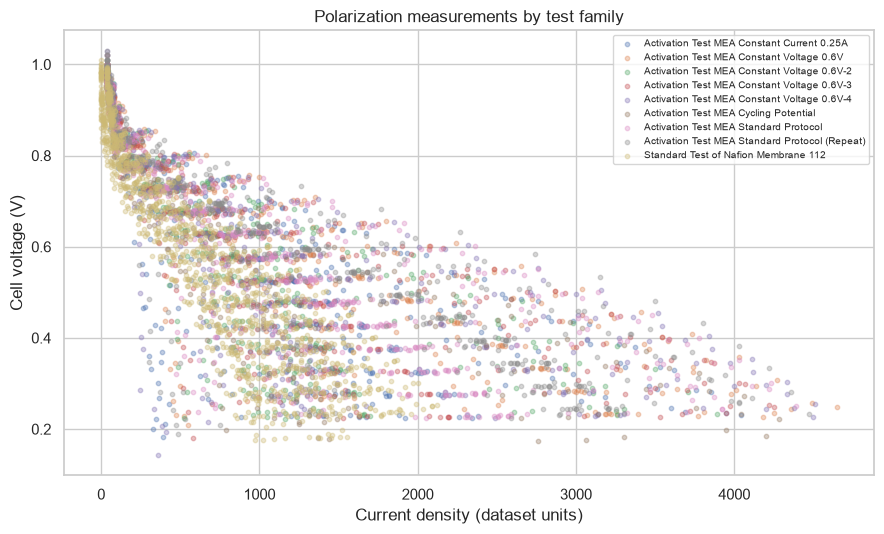

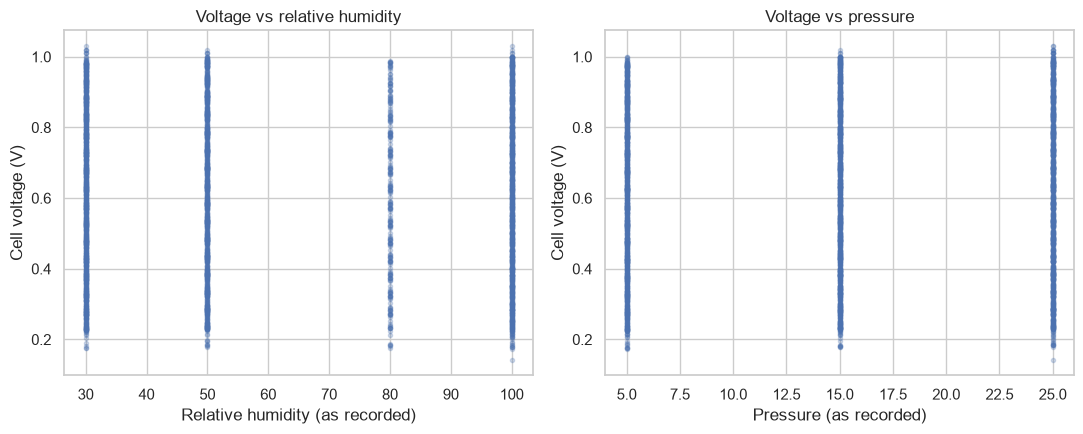

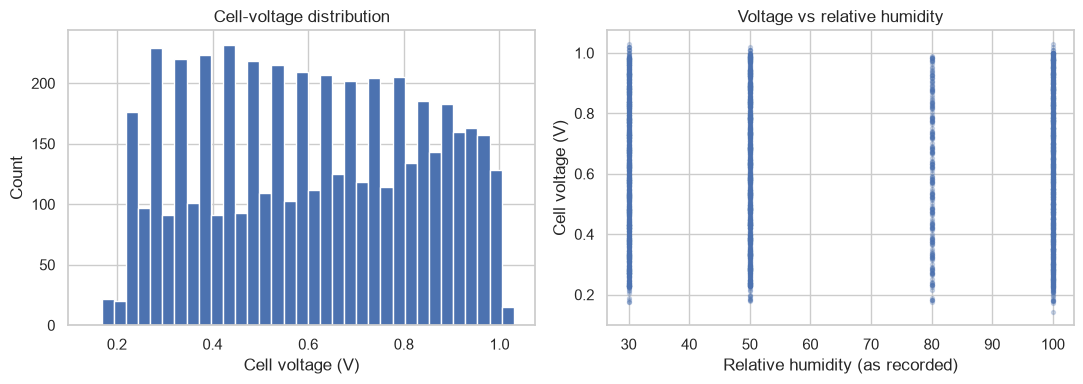

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for name, group in data.groupby("test_family"):
    sample = group.sample(min(len(group), 1200), random_state=RANDOM_STATE)
    ax.scatter(sample["current_density"], sample[TARGET], s=10, alpha=.35, label=name)
ax.set(xlabel="Current density (dataset units)", ylabel="Cell voltage (V)",
       title="Polarization measurements by test family")
ax.legend(fontsize=7, loc="best")
fig.tight_layout()
fig.savefig(ROOT / "polarization_profiles_by_family.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(data["relative_humidity"], data[TARGET], s=9, alpha=.25)
axes[0].set(xlabel="Relative humidity (as recorded)", ylabel="Cell voltage (V)",
            title="Voltage vs relative humidity")
axes[1].scatter(data["pressure"], data[TARGET], s=9, alpha=.25)
axes[1].set(xlabel="Pressure (as recorded)", ylabel="Cell voltage (V)",
            title="Voltage vs pressure")
fig.tight_layout()
fig.savefig(ROOT / "feature_target_relationships.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(data["cell_voltage"].dropna(), bins=35)
axes[0].set(title="Cell-voltage distribution", xlabel="Cell voltage (V)", ylabel="Count")
axes[1].scatter(data["relative_humidity"], data["cell_voltage"], s=8, alpha=.25)
axes[1].set(title="Voltage vs relative humidity", xlabel="Relative humidity (as recorded)", ylabel="Cell voltage (V)")
fig.tight_layout()
plt.show()

## 7A. Presentation-ready polarization and power-density curves

The scatterplot above combines measurements from multiple protocols. For presentation, the following figures preserve each original source file as a curve and show the conventional fuel-cell relationship between current density and cell voltage. The power-density plot is descriptive only; power density is deliberately **not** used as a model input because it is derived from current density and voltage.

The raw files are re-read here so the original `power_density` column can be plotted without adding it to the predictive feature matrix. Curves are sorted by current density for legibility; labels retain the test family and source filename.

Curve-level data: 5,005 points from 26 source files.


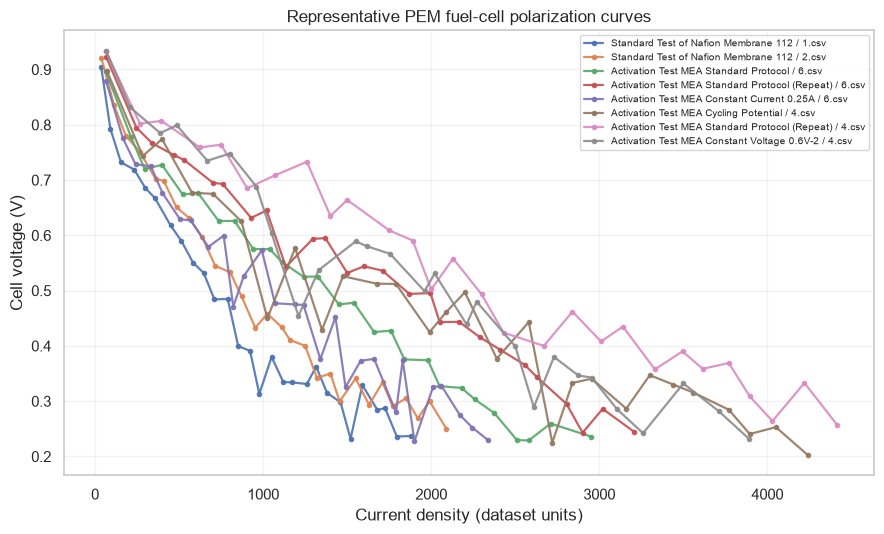

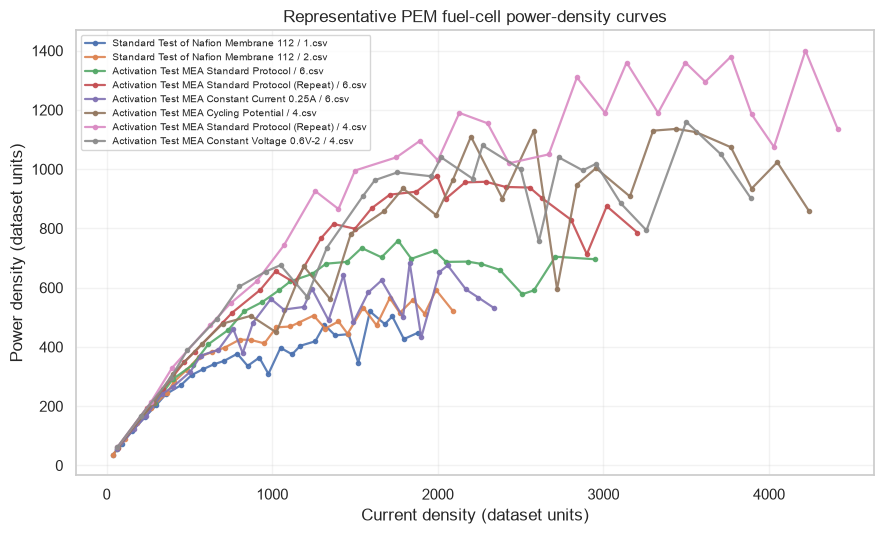

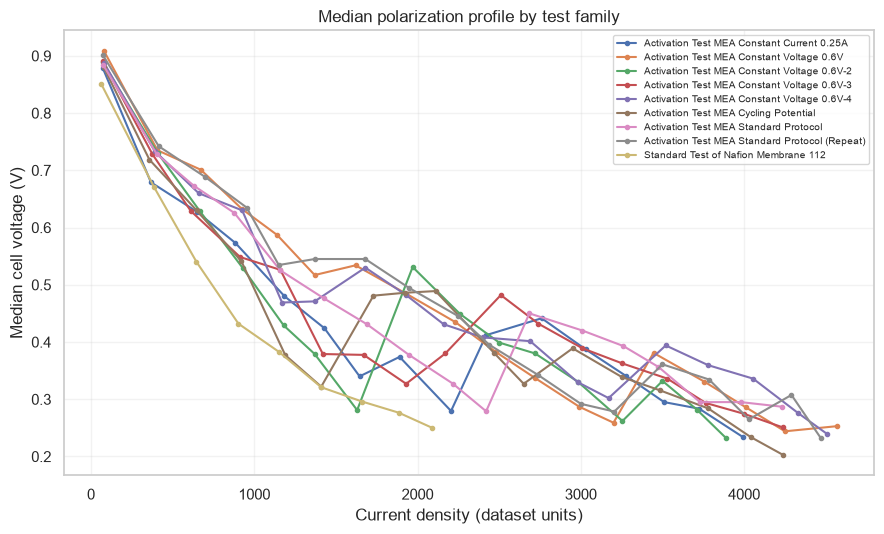

In [7]:
# Read the original polarization CSVs for curve-level plots. This is separate from
# the modeling table so derived power density is never accidentally used as a feature.
curve_frames = []
raw_dir = ROOT / "data" / "raw"
for csv_path in sorted(raw_dir.rglob("*.csv")):
    try:
        raw_curve = pd.read_csv(csv_path)
    except Exception:
        continue
    if not {"current_density", "cell_voltage"}.issubset(raw_curve.columns):
        continue
    curve = pd.DataFrame({
        "current_density": pd.to_numeric(raw_curve["current_density"], errors="coerce"),
        "cell_voltage": pd.to_numeric(raw_curve["cell_voltage"], errors="coerce"),
        "power_density": pd.to_numeric(raw_curve["power_density"], errors="coerce") if "power_density" in raw_curve else np.nan,
        "source_file": str(csv_path.relative_to(raw_dir)),
        "test_family": csv_path.parent.name,
    }).replace([np.inf, -np.inf], np.nan).dropna(subset=["current_density", "cell_voltage"])
    if len(curve) >= 3:
        curve_frames.append(curve)
curve_data = pd.concat(curve_frames, ignore_index=True)
curve_sizes = curve_data.groupby("source_file").size().sort_values(ascending=False)
selected_files = curve_sizes.head(min(8, len(curve_sizes))).index.tolist()
print(f"Curve-level data: {len(curve_data):,} points from {curve_data['source_file'].nunique()} source files.")

# Reduce repeated measurements to within-file current-density bins. Some protocols
# repeat operating points, so connecting every raw row can create misleading vertical
# jumps. Median bin profiles retain the curve shape while reducing overplotting.
def summarize_curve(frame, value_column, bins=28):
    frame = frame.dropna(subset=["current_density", value_column]).copy()
    if frame["current_density"].nunique() < 3:
        return frame.groupby("current_density", as_index=False)[value_column].median()
    frame["current_bin"] = pd.cut(frame["current_density"], bins=min(bins, frame["current_density"].nunique()), duplicates="drop")
    return (frame.groupby("current_bin", observed=True)
            .agg(current_density=("current_density", "median"), value=(value_column, "median"))
            .dropna().sort_values("current_density"))

# Figure 1: several original polarization curves (voltage vs current density).
fig, ax = plt.subplots(figsize=(9, 5.5))
for source in selected_files:
    raw_part = curve_data[curve_data["source_file"] == source]
    part = summarize_curve(raw_part, "cell_voltage")
    label = f"{raw_part['test_family'].iloc[0]} / {Path(source).name}"
    ax.plot(part["current_density"], part["value"], marker="o", markersize=3,
            linewidth=1.6, alpha=.9, label=label)
ax.set(xlabel="Current density (dataset units)", ylabel="Cell voltage (V)",
       title="Representative PEM fuel-cell polarization curves")
ax.grid(True, alpha=.25)
ax.legend(fontsize=7, loc="best")
fig.tight_layout()
fig.savefig(ROOT / "polarization_curves_representative.png", dpi=220, bbox_inches="tight")
plt.show()

# Figure 2: corresponding power-density curves where the source files provide them.
power_curves = curve_data.dropna(subset=["power_density"])
fig, ax = plt.subplots(figsize=(9, 5.5))
for source in selected_files:
    raw_part = power_curves[power_curves["source_file"] == source]
    if raw_part.empty:
        continue
    part = summarize_curve(raw_part, "power_density")
    label = f"{raw_part['test_family'].iloc[0]} / {Path(source).name}"
    ax.plot(part["current_density"], part["value"], marker="o", markersize=3,
            linewidth=1.6, alpha=.9, label=label)
ax.set(xlabel="Current density (dataset units)", ylabel="Power density (dataset units)",
       title="Representative PEM fuel-cell power-density curves")
ax.grid(True, alpha=.25)
ax.legend(fontsize=7, loc="best")
fig.tight_layout()
fig.savefig(ROOT / "power_density_curves_representative.png", dpi=220, bbox_inches="tight")
plt.show()

# Figure 3: protocol-level median voltage profiles using shared current-density bins.
# Binning is descriptive and avoids pretending that every row is an independent curve.
curve_data["current_bin"] = pd.cut(curve_data["current_density"], bins=18, duplicates="drop")
profile = (curve_data.groupby(["test_family", "current_bin"], observed=True)
           .agg(current_density=("current_density", "median"), voltage_median=("cell_voltage", "median"),
                voltage_q25=("cell_voltage", lambda x: x.quantile(.25)),
                voltage_q75=("cell_voltage", lambda x: x.quantile(.75)), n=("cell_voltage", "size"))
           .reset_index())
fig, ax = plt.subplots(figsize=(9, 5.5))
for family, part in profile.groupby("test_family"):
    part = part.sort_values("current_density")
    if len(part) < 2:
        continue
    ax.plot(part["current_density"], part["voltage_median"], marker=".", linewidth=1.5, label=family)
ax.set(xlabel="Current density (dataset units)", ylabel="Median cell voltage (V)",
       title="Median polarization profile by test family")
ax.grid(True, alpha=.25)
ax.legend(fontsize=7, loc="best")
fig.tight_layout()
fig.savefig(ROOT / "polarization_profiles_by_family.png", dpi=220, bbox_inches="tight")
plt.show()

---
## 8. Split once

Create a deterministic group-aware holdout. The split is reproduced in notebooks 02 and 03 using the same random seed. Entire source files are assigned to one partition, preventing points from the same source file appearing in both training and test data.

In [8]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.22, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(data, data[TARGET], groups=data[GROUP]))
train, test = data.iloc[train_idx].copy(), data.iloc[test_idx].copy()
assert set(train[GROUP]).isdisjoint(set(test[GROUP]))
print(f"Training: {len(train):,} rows from {train[GROUP].nunique()} source files")
print(f"Test:     {len(test):,} rows from {test[GROUP].nunique()} held-out source files")
print("Source-file overlap:", len(set(train[GROUP]) & set(test[GROUP])))
print("Held-out files:")
display(pd.Series(sorted(test[GROUP].unique()), name="held_out_source_file").to_frame())

Training: 3,692 rows from 20 source files
Test:     1,313 rows from 6 held-out source files
Source-file overlap: 0
Held-out files:


,held_out_source_file
0,Activation Test MEA Constant Current 0.25A/4.csv
1,Activation Test MEA Constant Voltage 0.6V-3/6.csv
2,Activation Test MEA Constant Voltage 0.6V-4/4.csv
3,Activation Test MEA Constant Voltage 0.6V-4/6.csv
4,Activation Test MEA Cycling Potential/5.csv
5,Standard Test of Nafion Membrane 112/1.csv


---
## 9. Baseline

The baseline predicts the mean cell voltage from the training partition for every test observation. It is a simple reference that more complex models must improve upon. Grouped cross-validation is used to estimate the baseline on training groups.

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

NUMERIC = ["current_density", "pressure", "relative_humidity"]
CATEGORICAL = ["test_family", "operating_set"]
numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler())])
categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocess = ColumnTransformer([("num", numeric_pipe, NUMERIC),
                                 ("cat", categorical_pipe, CATEGORICAL)])
X_train, y_train = train[FEATURES], train[TARGET]
cv = GroupKFold(n_splits=min(3, train[GROUP].nunique()))
baseline_pipe = Pipeline([("preprocess", preprocess),
                          ("model", DummyRegressor(strategy="mean"))])
baseline_scores = cross_validate(
    baseline_pipe, X_train, y_train, groups=train[GROUP], cv=cv,
    scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"},
    n_jobs=1
)
baseline_summary = pd.DataFrame({
    "metric": ["MAE (V)", "RMSE (V)"],
    "mean": [-baseline_scores["test_mae"].mean(), -baseline_scores["test_rmse"].mean()],
    "std": [baseline_scores["test_mae"].std(ddof=1), baseline_scores["test_rmse"].std(ddof=1)]
})
display(baseline_summary.round(5))
baseline_summary.to_csv(ROOT / "baseline_grouped_cv.csv", index=False)

,metric,mean,std
0,MAE (V),0.19817,0.00146
1,RMSE (V),0.22866,0.00143


---
## 10. Into notebook 02

**Feature set:** `current_density`, `pressure`, `relative_humidity`, `test_family`, and `operating_set`.

**Preprocessing:** median imputation and scaling for numeric columns; most-frequent imputation and one-hot encoding for categorical columns. All learned preprocessing stays inside the scikit-learn pipeline.

**Validation:** same deterministic group holdout; grouped cross-validation on training files only.

**Next:** compare regression model families on the same folds and tune the strongest candidate. The test set remains untouched until notebook 03.